# Practice 3 — Get started with Hugging Face

Notebook này chỉ **gọi code trong `src/`** và hiện kết quả. Muốn sửa logic thì sửa file `.py`, muốn đổi tham số thì sửa `configs/exercise_2.yaml`.

**Chuẩn bị:** tải cả thư mục `Lab 3` lên `MyDrive`, chọn **Runtime → Change runtime type → T4 GPU**, rồi bấm **Run all**. Drive cần trống khoảng 1 GB cho checkpoint.

## Chuẩn bị môi trường

In [1]:
import os
from google.colab import drive

drive.mount("/content/drive")

# Nếu bạn đặt thư mục ở nơi khác trên Drive thì sửa đường dẫn này.
PROJECT_DIR = "/content/drive/MyDrive/Lab 3"
assert os.path.isdir(f"{PROJECT_DIR}/src"), f"Không thấy code tại {PROJECT_DIR}"
os.chdir(PROJECT_DIR)
os.environ["PYTHONPATH"] = "src"
print("Thư mục làm việc:", os.getcwd())

Mounted at /content/drive
Thư mục làm việc: /content/drive/MyDrive/Lab 3


In [2]:
!pip install -q -r requirements.txt

In [3]:
import torch

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CẢNH BÁO: chưa bật GPU. Các KPI tốc độ và VRAM sẽ không đo được.")

GPU: Tesla T4


## Exercise 1 — Sentiment Analysis with Hugging Face

Bước 1 đã làm ở phần cài thư viện. Lệnh dưới đây làm bước 2–4: dùng model có sẵn, tokenize câu và phân tích cảm xúc.

In [4]:
!python -m exercise_1.sentiment_analysis --text "Hôm qua em tuyệt lắm!"

config.json: 100% 851/851 [00:00<00:00, 4.32MB/s]
tokenizer_config.json: 100% 1.20k/1.20k [00:00<00:00, 3.81MB/s]
vocab.txt: 100% 996k/996k [00:00<00:00, 88.4MB/s]
tokenizer.json: 100% 2.92M/2.92M [00:00<00:00, 119MB/s]
special_tokens_map.json: 100% 125/125 [00:00<00:00, 640kB/s]

model.safetensors: downloading bytes:  38% 207M/541M [00:02<00:01, 214MB/s, 15.4MB/s  ]
model.safetensors: downloading bytes:  58% 315M/541M [00:02<00:01, 206MB/s, 26.9MB/s  ]
model.safetensors: downloading bytes:  69% 374M/541M [00:02<00:00, 228MB/s, 30.1MB/s  ]
model.safetensors: downloading bytes:  88% 474M/541M [00:03<00:00, 275MB/s, 38.1MB/s  ]
model.safetensors: downloading bytes:  94% 511M/541M [00:03<00:00, 244MB/s, 43.9MB/s  ]
model.safetensors: downloading bytes: 100% 511M/511M [00:03<00:00, 136MB/s, 44.2MB/s  ]
model.safetensors: reconstructing file: 100% 541M/541M [00:03<00:00, 145MB/s, 47.8MB/s  ]
Loading weights: 100% 104/104 [00:00<00:00, 4164.07it/s]
Sentence: Hôm qua em tuyệt lắm!
Tokens: ['H

In [5]:
!python -m exercise_1.sentiment_analysis --text "The movie was boring and far too long."

Loading weights: 100% 104/104 [00:00<00:00, 3976.77it/s]
Sentence: The movie was boring and far too long.
Tokens: ['The', 'movie', 'was', 'bor', '##ing', 'and', 'far', 'too', 'long', '.']
Sentiment: Negative
Score: 0.8546


## Exercise 2 — Finetuning a Pretrained Model for Binary Text Classification

### Smoke test
Chạy 2 batch để kiểm tra shape, loss và gradient trước khi train thật, cùng với các test logic.

In [6]:
!python -m pytest tests -q -s

config.json: 100% 483/483 [00:00<00:00, 1.64MB/s]
tokenizer_config.json: 100% 48.0/48.0 [00:00<00:00, 222kB/s]
vocab.txt: 100% 232k/232k [00:00<00:00, 777kB/s]
tokenizer.json: 100% 466k/466k [00:00<00:00, 970kB/s]
README.md: 100% 7.81k/7.81k [00:00<00:00, 22.1MB/s]

plain_text/train-00000-of-00001.parquet: downloading bytes:  23% 4.76M/21.0M [00:01<00:04, 3.82MB/s]
plain_text/train-00000-of-00001.parquet: downloading bytes: 100% 20.9M/20.9M [00:01<00:00, 13.4MB/s, 2.02MB/s  ]
plain_text/train-00000-of-00001.parquet: reconstructing file: 100% 21.0M/21.0M [00:01<00:00, 13.4MB/s, 2.03MB/s  ]

plain_text/test-00000-of-00001.parquet: downloading bytes:  64% 13.1M/20.5M [00:01<00:00, 12.4MB/s,  681kB/s  ]
plain_text/test-00000-of-00001.parquet: downloading bytes: 100% 20.4M/20.4M [00:01<00:00, 13.2MB/s, 1.96MB/s  ]
plain_text/test-00000-of-00001.parquet: reconstructing file: 100% 20.5M/20.5M [00:01<00:00, 13.3MB/s, 1.98MB/s  ]

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes: 

### Bước 2 và 4: dữ liệu IMDB và tiền xử lý

In [7]:
!python -m exercise_2.data

train {'samples': 1000, 'negative': 512, 'positive': 488}
val {'samples': 200, 'negative': 91, 'positive': 109}
test {'samples': 200, 'negative': 104, 'positive': 96}
duplicate_texts {'train_val': 0, 'train_val_vs_test': 0}

Mẫu đầu tiên của tập train: There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. Fortier's plot are far more complicated... Fortier looks more like Prime Suspect, if we have to spot  ...


### Bước 3: model và tokenizer

In [8]:
!python -m exercise_2.model

Loading weights: 100% 100/100 [00:00<00:00, 4307.95it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Linear(in_features=768, out_features=768, bias=True)
Dropout(p=0.2, inplace=False)
Linear(in_features=768, out_features=2, bias=True)
Tổng tham số: 66,955,010 | C

### Bước 5 và 6: khai báo tham số, tạo `Trainer` và fine-tune
Lưu các mốc `final_epoch`, `best_val_loss`, `best_val_acc`, `best` vào `checkpoints/`. Nếu Colab ngắt phiên, chỉ cần chạy lại từ đầu.

In [9]:
!python -m exercise_2.training

Loading weights: 100% 100/100 [00:00<00:00, 3960.63it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Map: 100% 1000/1000 [00:00<00:00, 1106.32 examples/s]
Map: 100% 200/200 [00:00<00:00, 1108.56 examples/s]
{'loss': '0.6873', 'grad_norm': '1.111', 'learning_rate'

### Bước 7: đánh giá mốc `best` trên tập test

In [10]:
!python -m exercise_2.evaluation

Loading weights: 100% 104/104 [00:00<00:00, 8518.52it/s]
Map: 100% 200/200 [00:00<00:00, 1285.53 examples/s]
100% 13/13 [00:02<00:00,  5.22it/s]
Validation Accuracy: 0.89 | mục tiêu 0.85 | Đạt
Test Accuracy: 0.87 | mục tiêu 0.85 | Đạt
Test Macro F1: 0.8696741854636592 | mục tiêu 0.85 | Đạt
Thời gian train (giây/epoch): 6.573524484000018 | mục tiêu 180 | Đạt
Độ trễ suy luận (ms/mẫu): 7.635190550000175 | mục tiêu 25 | Đạt
VRAM cao nhất (GB): 1.6800165176391602 | mục tiêu 4.0 | Đạt
RAM cao nhất (GB): 1.9079170227050781 | mục tiêu 6.0 | Đạt
Test Accuracy 0.870 ± 0.047 (khoảng tin cậy 95%)


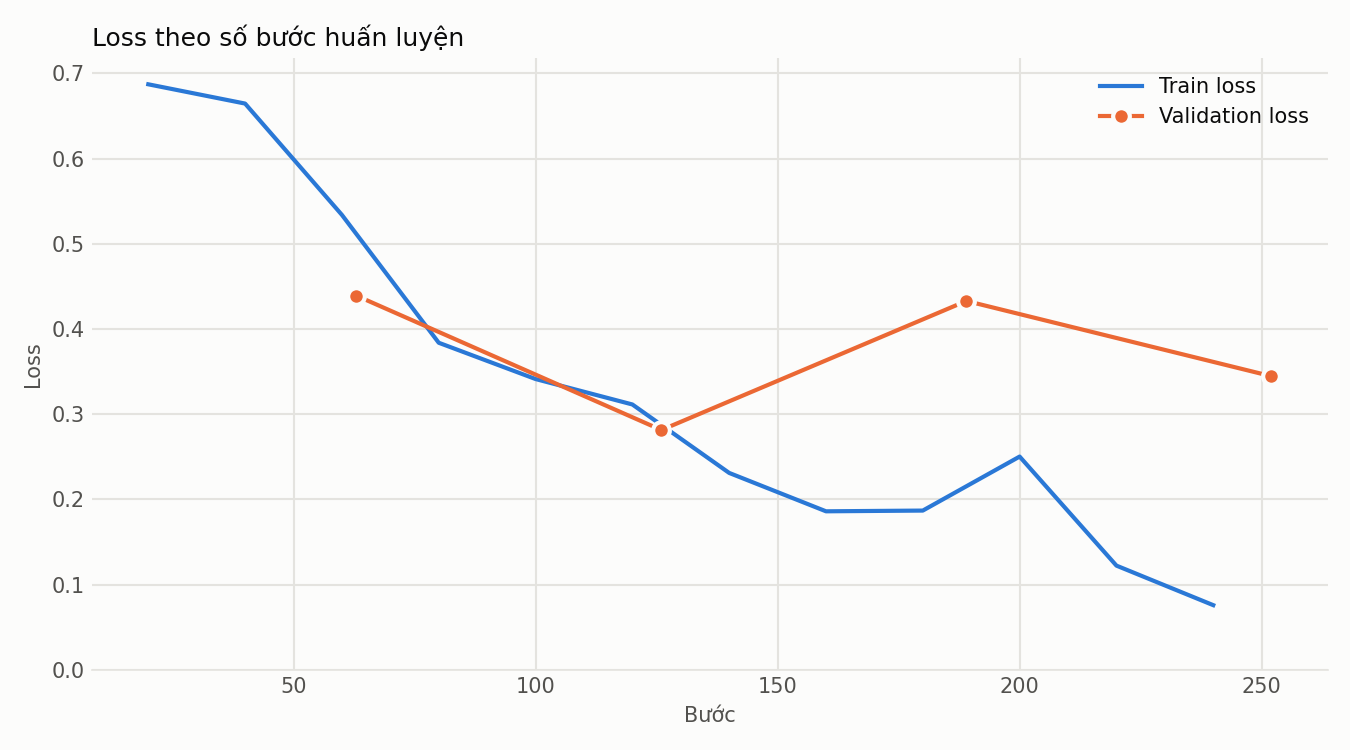

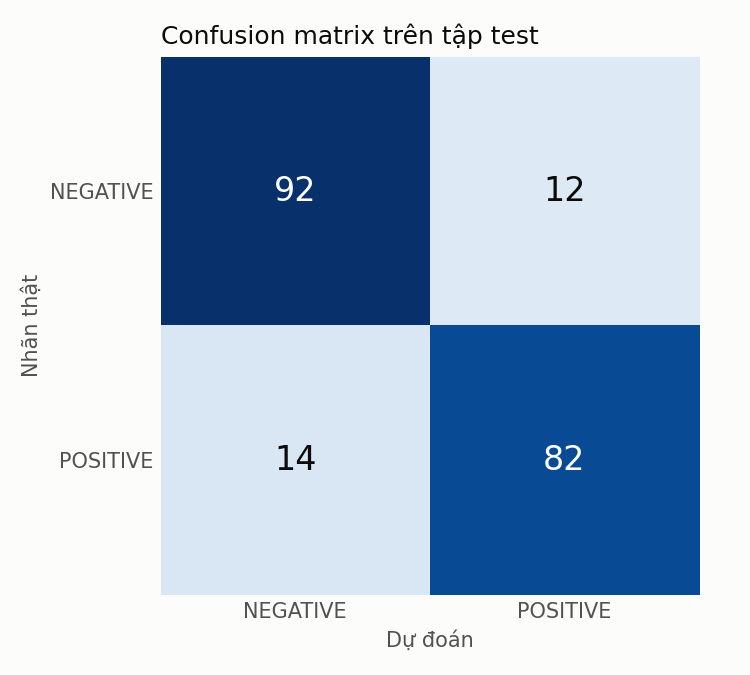

In [11]:
from IPython.display import Image, display

display(Image("reports/figures/loss_curve.png"))
display(Image("reports/figures/confusion_matrix.png"))

### Demo với câu thực tế

In [12]:
!python -m exercise_2.demo

Loading weights: 100% 104/104 [00:00<00:00, 2285.65it/s]
Câu: This movie was an absolute masterpiece! The acting and plot were brilliant.
-> POSITIVE (98.03%), nhãn thật: POSITIVE

Câu: Waste of time. The acting was terrible and the storyline made no sense.
-> NEGATIVE (98.49%), nhãn thật: NEGATIVE

Câu: It was an average film, neither great nor awful.
-> NEGATIVE (91.48%), nhãn thật: None



## Kết quả

Toàn bộ số liệu nằm trong `reports/metrics.json` và ảnh trong `reports/figures/` trên Drive. Đây là nguồn để điền `docs/evaluation.md` và `docs/demo.md`.

In [13]:
import json
import pandas as pd

report = json.load(open("reports/metrics.json", encoding="utf-8"))
display(pd.DataFrame(report["training"]["epochs"]))
display(pd.DataFrame(report["evaluation"]["kpi"]))
print("Phiên bản thư viện:", report["training"]["library_versions"])

,epoch,train_loss,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_macro_f1,train_seconds,flags
0,1,0.628674,0.439201,0.805,0.960526,0.669725,0.789189,0.803897,6.592803,"[final_epoch, best_val_loss, best_val_acc]"
1,2,0.345617,0.281511,0.885,0.905660,0.880734,0.893023,0.884349,7.044343,"[final_epoch, best_val_loss, best_val_acc]"
2,3,0.201418,0.433014,0.850,0.964706,0.752294,0.845361,0.849865,6.306618,[final_epoch]
3,4,0.149559,0.344687,0.890,0.939394,0.853211,0.894231,0.889824,6.350334,"[final_epoch, best_val_acc]"


,metric,value,target,status
0,Validation Accuracy,0.890000,0.85,Đạt
1,Test Accuracy,0.870000,0.85,Đạt
2,Test Macro F1,0.869674,0.85,Đạt
3,Thời gian train (giây/epoch),6.573524,180.00,Đạt
4,Độ trễ suy luận (ms/mẫu),7.635191,25.00,Đạt
5,VRAM cao nhất (GB),1.680017,4.00,Đạt
6,RAM cao nhất (GB),1.907917,6.00,Đạt


Phiên bản thư viện: {'torch': '2.11.0+cu130', 'transformers': '5.22.0', 'datasets': '4.8.5', 'evaluate': '0.4.6', 'accelerate': '1.15.0', 'scikit-learn': '1.6.1'}
